# E. Filter and Rank Pages for Scraping

## Aim

Prepare a useful list of web pages to scrape for the community questions. We use the English link labels and translated page names already in our data. We do not fetch any candidate pages in this notebook.

The workflow is: clean the candidates, compare them with the search items, review the strongest matches and save a unique URL list. Every inclusion and exclusion can be traced back to its evidence.

The final list contains promising sources to investigate. It does not prove that a page answers a question, is current, or is written in English.

## 1. Load the data and settings

Load the search items from D and candidate URLs from C. Also load B's English link labels so we can use all available labels rather than only five examples per URL.

Run from `new/notebooks`. Install the project requirements first. The semantic models run locally; on a new machine, download their pinned versions with `../../.venv/bin/python ../scripts/download_ranking_models.py`. That setup downloads public model files only.

The helper functions are in `../src/candidate_ranking.py`. Model files and cached calculations stay in the ignored `new/.cache/ranking` folder.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import importlib.metadata

DATA_DIR = Path("../data")
REFERENCE_DIR = DATA_DIR / "reference"
OUTPUT_DIR = DATA_DIR / "processed"
CACHE_DIR = Path("../.cache/ranking").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HOME"] = str(CACHE_DIR / "hf_home")
os.environ["HF_HUB_CACHE"] = str(CACHE_DIR / "models")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["MPLCONFIGDIR"] = str(Path("../.matplotlib-cache").resolve())
sys.path.insert(0, str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import MiniBatchKMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from src.candidate_ranking import (
    prepare_candidates, phrase_scores, lexical_scores, embedding_scores,
    retrieve_pairs, rerank_pairs, select_pairs, coverage_report, ranked_positions,
)

search_items_df = pd.read_csv(DATA_DIR / "interim/community_search_items.csv")
urls_df = pd.read_csv(DATA_DIR / "interim/discovered_urls_for_scoring.csv")
enriched_df = pd.read_csv(DATA_DIR / "interim/discovered_links_enriched.csv")
models = json.loads((REFERENCE_DIR / "ranking_models.json").read_text())
policy = json.loads((REFERENCE_DIR / "selection_policy.json").read_text())
print(f"{len(search_items_df)} search items; {len(urls_df):,} candidate entries")

21 search items; 3,851 candidate entries


## 2. Filter obvious noise and prepare English destination text

Keep an audit row for every input URL. Exclude non-web links and clear privacy, cookie, login and sharing endpoints. Flag job listings, disclaimers, login help and missing labels for review. Contact pages and PDFs remain available.

Page-type rules use exact English destination labels. Relevance scoring uses `full_url_slug_en`, `link_text_en` and `url_section_en`. The Dutch URL is retained as the address to scrape, not as a relevance feature. A warning flags a few obvious untranslated fragments; this is a limited check, not language detection.

We keep title, link labels and website section separate. C's combined `url_text` is omitted because source-page topics can make an unrelated destination look relevant. Source-page columns stay available for traceability.

In [2]:
prepared_urls_df = prepare_candidates(urls_df, enriched_df)
candidate_urls_df = (
    prepared_urls_df.loc[prepared_urls_df["filter_status"].ne("exclude")]
    .sort_values("canonical_url")
    .drop_duplicates("canonical_url")
    .reset_index(drop=True)
)
filter_summary_df = prepared_urls_df.groupby(["filter_status", "filter_reason"]).size().reset_index(name="url_count")
display(filter_summary_df)
with pd.option_context("display.max_colwidth", 100):
    display(candidate_urls_df[["full_url", "title_text", "anchor_text", "section_text"]].head(8))
print("Scoring candidates:", len(candidate_urls_df))
print("Possible untranslated fragments:", candidate_urls_df["english_field_warning"].ne("").sum())

,filter_status,filter_reason,url_count
0,exclude,Not a web page link,29
1,exclude,Privacy/cookie page,7
2,exclude,Share/navigation endpoint,2
3,keep,Available for relevance scoring,3797
4,review,Disclaimer,3
5,review,Job/volunteer listing,3
6,review,Link label indicates login required,8
7,review,Login help,1
8,review,No useful destination label,1


,full_url,title_text,anchor_text,section_text
0,http://iknl.nl/getmedia/487ed4b8-4b77-4672-b4e5-bc6de00a26f4/HB_levercel-en-galwegkanker_def1_3.pdf,hb levercel en galwegkanker def1 3.pdf,liver cell and biliary tract cancer report in the netherlands. liver cell and biliary tract canc...,getmedia
1,http://iknl.nl/medewerkers/maaike-van-der-aa,maaike of the aa,maaike van der aa,collaborators
2,http://www.zorgwijzer.nl/,homepage,www.zorgwijzer.nl,homepage
3,http://www.zorgwijzer.nl/zorgvergelijker,care comparator,www.zorgwijzer.nl/zorgvergelijker,care comparator
4,https://iknl.nl/,homepage,f5b3a27f 5084 4890 9e2e 7a173532f362 created with sketch tool.,homepage
5,https://iknl.nl/Eierstokkanker-Nederland-2025,ovarian cancer netherlands 2025,ovarian cancer in the netherlands 2025,ovarian cancer netherlands 2025
6,https://iknl.nl/Kankersoorten,types of cancer,types of cancer,types of cancer
7,https://iknl.nl/NKR,nkr,dutch cancer registry,nkr


Scoring candidates: 3809
Possible untranslated fragments: 2


## 3. Give each search item a clear query and useful phrases

Keep D's original text. Add an English retrieval query that makes the intended topic explicit, and a small vocabulary of related phrases. For example, “How do I request one?” is expanded to requesting a second opinion.

These are assistant-authored search aids, saved in editable reference CSVs. They are not extra statements extracted from the PDF. Specific phrases have weight 3; supporting words have weight 1. Match complete words and phrases, including simple plurals, so “long” does not match “prolonged”.

In [3]:
query_profiles_df = pd.read_csv(REFERENCE_DIR / "community_query_profiles.csv")
vocabulary_df = pd.read_csv(REFERENCE_DIR / "community_search_vocabulary.csv")
queries_df = search_items_df.merge(query_profiles_df, on="item_id", how="left", validate="one_to_one")
if queries_df["retrieval_query"].isna().any():
    raise ValueError("A search item is missing its English query profile.")
with pd.option_context("display.max_rows", 25, "display.max_colwidth", 110):
    display(queries_df[["item_id", "item_text", "retrieval_query"]])
display(vocabulary_df.head(10))
phrase_matrix, specific_matches, phrase_evidence = phrase_scores(queries_df, candidate_urls_df, vocabulary_df)

,item_id,item_text,retrieval_query
0,1,How do referrals work in the Netherlands?,How do I get a referral from a GP to a hospital specialist in the Netherlands?
1,2,Can I choose my hospital or specialist?,Can a cancer patient choose their hospital or specialist? Hospital choice and expert care.
2,3,Can I change doctors?,"Can I change my doctor, switch specialist or transfer care to another hospital?"
3,4,How long should I expect to wait for appointments or treatment?,"How long do patients wait for appointments, diagnosis and cancer treatment? Waiting times."
4,5,What can I do if I feel the process is too slow?,What can I do about long waiting times? Care mediation and waiting list mediation through an insurer.
5,6,Is it normal to wait between steps?,"Why is there a wait between cancer diagnosis, tests and treatment? Waiting times between steps."
6,7,How are treatment decisions made?,"How are cancer treatment decisions made? Shared decision making, treatment plans and discussing options wi..."
7,8,Can I ask for alternative options?,Can I discuss other cancer treatment options and choose between treatments with my doctor?
8,9,Do I have time to decide?,Do I have time to think and decide about cancer treatment? Treatment decisions and decision aids.
9,10,Am I allowed to get a second opinion? Also in another country.,"Can I request a second opinion about cancer, including at a hospital abroad?"


,item_id,phrase,weight,specificity,source
0,1,referral,3,specific,assistant_authored_english_vocabulary
1,1,referrals,3,specific,assistant_authored_english_vocabulary
2,1,referred,3,specific,assistant_authored_english_vocabulary
3,1,general practitioner,3,specific,assistant_authored_english_vocabulary
4,1,gp,3,specific,assistant_authored_english_vocabulary
5,1,specialist referral,3,specific,assistant_authored_english_vocabulary
6,1,hospital,1,supporting,assistant_authored_english_vocabulary
7,1,specialist,1,supporting,assistant_authored_english_vocabulary
8,1,doctor,1,supporting,assistant_authored_english_vocabulary
9,2,hospital choice,3,specific,assistant_authored_english_vocabulary


## 4. Measure word and phrase similarity with TF-IDF

TF-IDF gives more weight to distinctive terms than to common words. We use individual words and two-word phrases, then compare vectors with cosine similarity.

Fit each vocabulary on the candidate texts, then transform the queries with that vocabulary. Destination titles and link labels each receive 45% of the lexical score; broad website sections receive 10%. Source-page topics and discovery counts receive no relevance weight.

These are starting weights chosen for this dataset, not values learned from labelled examples.

In [4]:
FIELD_WEIGHTS = {"title_text": 0.45, "anchor_text": 0.45, "section_text": 0.10}
tfidf_matrix, field_scores, lexical_explanation = lexical_scores(queries_df, candidate_urls_df, FIELD_WEIGHTS)
print("Question-by-URL score matrix:", tfidf_matrix.shape)

Question-by-URL score matrix: (21, 3809)


## 5. Match meaning with sentence embeddings

An English sentence-transformer model helps connect related wording, such as physical therapy and physiotherapy. Encode the expanded queries and destination text, normalise the vectors, and compare them with cosine similarity.

The model runs locally using pinned files. Results are cached using the model version and input text, so changed data is recalculated. Text longer than the model's limit is flagged below.

In [5]:
semantic_matrix, document_embeddings, embedding_truncated = embedding_scores(
    queries_df, candidate_urls_df, models["embedding"], CACHE_DIR,
)
candidate_urls_df["embedding_text_truncated"] = embedding_truncated
print("Embedding model:", models["embedding"]["model_id"])
print("Texts truncated at 256 model tokens:", int(embedding_truncated.sum()))

Embedding model: sentence-transformers/multi-qa-MiniLM-L6-cos-v1
Texts truncated at 256 model tokens: 0


## 6. Combine the rankings and rerank the strongest candidates

Take the top 40 positive matches from each method for every search item. Their union gives a broader pool than any one method alone.

Use reciprocal rank fusion: add `1 / (60 + rank)` for TF-IDF and semantic ranks, plus half that weight for phrase ranks. Only positive evidence contributes. This avoids adding scores with different scales directly.

A cross-encoder then reads each expanded English query alongside the destination text. Add half-weight reciprocal reranker rank to the fused score. The reranker helps order the pool, but it does not replace the other evidence. Its raw scores are not probabilities.

In [6]:
match_scores_df, method_ranks = retrieve_pairs(
    queries_df, candidate_urls_df, tfidf_matrix, semantic_matrix, phrase_matrix,
    specific_matches, phrase_evidence, lexical_explanation,
    retrieval_depth=policy["retrieval_depth"], rrf_k=policy["rrf_k"],
)
match_scores_df = rerank_pairs(match_scores_df, models["reranker"], CACHE_DIR)
print(f"Compared {len(match_scores_df):,} retrieved question–URL pairs with the reranker.")
with pd.option_context("display.max_colwidth", 85):
    display(match_scores_df.groupby("item_id").head(2)[[
        "item_id", "destination_text", "tfidf_score", "semantic_score", "matched_phrases", "final_rank"
    ]])

Compared 1,855 retrieved question–URL pairs with the reranker.


,item_id,destination_text,tfidf_score,semantic_score,matched_phrases,final_rank
0,1,about the cancer referral guide. cancer referral guide. help and support,0.223031,0.380532,referral,1
1,1,healthcare netherlands. healthcare in the netherlands. dutch healthcare system. faq,0.145734,0.543954,,2
86,2,website about hospital choice. hospital choice website. wherewithal,0.382403,0.610902,hospital choice; hospital; choice,1
87,2,rare cancer inadequate access expert care. rare cancer patient has insufficient a...,0.245796,0.563169,expert care,2
161,3,hospital choice checklist. wherewithal,0.113438,0.385659,hospital choice,1
162,3,website about hospital choice. hospital choice website. wherewithal,0.111476,0.446760,hospital choice,2
249,4,which health insurers have a medical acceptance. which health insurers have a med...,0.043310,0.502575,waiting,1
250,4,treatment. types of cancer,0.203944,0.443029,,2
326,5,which health insurers have a medical acceptance. which health insurers have a med...,0.082758,0.447164,waiting,1
327,5,"psychological care. mental health problems, waiting lists and additional coverage...",0.102474,0.327213,waiting list; waiting,2


## 7. Compare methods and inspect mistakes

The small reference set below contains assistant-reviewed metadata examples: useful topic matches and misleading alternatives. It is a development check, not an independent benchmark or a judgement of page contents.

Compare how each method ranks the relevant example against its misleading alternative. The review sample exported later leaves a separate human-label column blank for a proper assessment. We cannot claim retrieval precision or recall across all pages without those labels and page content.

In [7]:
benchmark_df = pd.read_csv(REFERENCE_DIR / "metadata_retrieval_checks.csv")
url_index = dict(zip(candidate_urls_df["full_url"], candidate_urls_df.index))
item_index = dict(zip(queries_df["item_id"], queries_df.index))
final_ranks = {(row.item_id, row.full_url): row.final_rank for row in match_scores_df.itertuples()}
comparison_rows = []
for check in benchmark_df.itertuples():
    qi = item_index[check.item_id]
    positive = url_index[check.useful_url]
    negative = url_index[check.misleading_url]
    for method in ["tfidf", "semantic", "phrase", "hybrid"]:
        if method == "hybrid":
            good_rank = final_ranks.get((check.item_id, check.useful_url), len(candidate_urls_df)+1)
            bad_rank = final_ranks.get((check.item_id, check.misleading_url), len(candidate_urls_df)+1)
        else:
            matrix = {"tfidf":tfidf_matrix, "semantic":semantic_matrix, "phrase":phrase_matrix}[method]
            good_rank = int(method_ranks[method][qi, positive]) if matrix[qi, positive] > 0 else len(candidate_urls_df)+1
            bad_rank = int(method_ranks[method][qi, negative]) if matrix[qi, negative] > 0 else len(candidate_urls_df)+1
        comparison_rows.append({"item_id":check.item_id, "method":method,
            "useful_rank":good_rank, "misleading_rank":bad_rank,
            "useful_ranked_first":good_rank < bad_rank, "useful_in_top_10":good_rank <= 10})
method_checks_df = pd.DataFrame(comparison_rows)
method_comparison_df = method_checks_df.groupby("method").agg(
    examples=("item_id", "size"), useful_ranked_first=("useful_ranked_first", "sum"),
    useful_in_top_10=("useful_in_top_10", "sum"),
).reset_index()
display(method_comparison_df)

,method,examples,useful_ranked_first,useful_in_top_10
0,hybrid,11,10,10
1,phrase,11,11,9
2,semantic,11,10,5
3,tfidf,11,7,6


## 8. Group similar pages to understand the candidate set

Cluster the candidate embeddings into 18 exploratory groups and show their strongest English terms. These groups help us see repeated topics and where the shortlist comes from. They do not decide whether a page is relevant, and they do not replace the six source themes in D.

In [8]:
cluster_model = MiniBatchKMeans(n_clusters=18, random_state=42, n_init=5, batch_size=256)
candidate_urls_df["topic_cluster"] = cluster_model.fit_predict(document_embeddings)
cluster_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1,2), min_df=2)
cluster_terms = cluster_vectorizer.fit_transform(candidate_urls_df["destination_text"])
term_names = cluster_vectorizer.get_feature_names_out()
cluster_rows = []
for cluster_id, group in candidate_urls_df.groupby("topic_cluster"):
    mean_weights = np.asarray(cluster_terms[group.index].mean(axis=0)).ravel()
    top_terms = term_names[np.argsort(-mean_weights)[:6]]
    cluster_rows.append({"topic_cluster":cluster_id, "candidate_urls":len(group),
                         "top_english_terms":", ".join(top_terms)})
cluster_summary_df = pd.DataFrame(cluster_rows)
display(cluster_summary_df)

,topic_cluster,candidate_urls,top_english_terms
0,0,48,"radiation, cancer, radiation therapy, therapy,..."
1,1,552,"cancer, types cancer, types, cancer types, num..."
2,2,258,"care, caregivers, remuneration, therapy, hospi..."
3,3,210,"pdf, file, download, kb, kb file, corona"
4,4,199,"cancer, help, support, help support, learn, ask"
5,5,459,"pain, inflammation, disease, eye, anatomically..."
6,6,178,"child, disorder, anxiety, pregnant, asthma, adhd"
7,7,141,"health, insurance, health insurance, faq, heal..."
8,8,265,"cancer, types cancer, types, cancer types, sto..."
9,9,228,"minutes, minutes overview, overview, 02, exerc..."


## 9. Choose a manageable scraping list

Require agreement between phrase/lexical and semantic evidence. Pages without a specific phrase need stronger semantic and lexical scores. A loose reranker floor removes very weak matches; it is not treated as a calibrated relevance threshold.

Prefer information and service pages over peer discussions and news, with at most eight URLs per item and three from one domain. Very similar metadata from the same domain is deprioritised within an item; those URLs remain in the audit because similar labels do not prove identical page content.

The settings are in `selection_policy.json`. The metadata review removes misleading matches and explicitly includes a few relevant directories missed by the thresholds. Reviewed inclusions are prioritised, but cannot override an exclusion or pending page review. These decisions are recorded separately from model scores. No weak match is added just to fill a question's quota.

In [9]:
review_decisions_df = pd.read_csv(REFERENCE_DIR / "metadata_review_decisions.csv").fillna("")
selection_df = select_pairs(match_scores_df, document_embeddings, policy, review_decisions_df)
selected_pairs_df = selection_df.loc[selection_df["selection_status"].eq("selected")].copy()
coverage_df = coverage_report(queries_df, selection_df)
display(coverage_df[["item_id", "item_text", "selected_urls", "coverage_status"]])

# Show the effect of nearby choices instead of calling one cutoff optimal.
sensitivity_rows = []
for minimum in [0.30, 0.35, 0.40, 0.45]:
    settings = {**policy, "min_semantic_score":minimum}
    result = select_pairs(match_scores_df, document_embeddings, settings, review_decisions_df)
    selected = result.loc[result["selection_status"].eq("selected")]
    sensitivity_rows.append({"minimum_semantic_score":minimum,
        "unique_urls":selected["canonical_url"].nunique(), "items_with_candidates":selected["item_id"].nunique()})
sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)

,item_id,item_text,selected_urls,coverage_status
0,1,How do referrals work in the Netherlands?,0,gap_in_current_metadata
1,2,Can I choose my hospital or specialist?,4,candidate_sources_found
2,3,Can I change doctors?,0,gap_in_current_metadata
3,4,How long should I expect to wait for appointme...,0,gap_in_current_metadata
4,5,What can I do if I feel the process is too slow?,0,gap_in_current_metadata
5,6,Is it normal to wait between steps?,0,gap_in_current_metadata
6,7,How are treatment decisions made?,8,candidate_sources_found
7,8,Can I ask for alternative options?,5,candidate_sources_found
8,9,Do I have time to decide?,5,candidate_sources_found
9,10,Am I allowed to get a second opinion? Also in ...,0,gap_in_current_metadata


,minimum_semantic_score,unique_urls,items_with_candidates
0,0.30,50,13
1,0.35,47,12
2,0.40,44,12
3,0.45,39,11


## 10. Inspect the final list and the gaps

Combine selections into one row per canonical URL. Keep all matched item IDs and themes, evidence, destination text and source examples. Scores set scrape priority; they are not medical-quality or source-trust scores.

A question with no selected URL is a gap in this discovery dataset, not proof that the information does not exist online. Even a selected source may cover only part of a question. Those limits are recorded in the coverage table.

,scrape_priority,full_url,matched_item_ids,destination_text
0,1,https://www.kanker.nl/gevolgen-van-kanker/vruchtbaarheid-en-kanker,17,fertility and cancer. consequences of cancer
1,2,https://www.kanker.nl/gevolgen-van-kanker/niet-meer-beter-worden/informatie-voor-naast...,13,practical help and support. consequences of cancer
2,3,https://www.kanker.nl/hulp-en-ondersteuning/stel-je-vraag-aan-een-professional/voeding...,16,nutrition and cancer. learn more about: nutrition and cancer. help and support
3,4,https://www.zorginstituutnederland.nl/verzekerde-zorg/v/vruchtbaarheidsbehandeling-zvw,17,fertility treatment zvw. fertility treatment (zvw). insured care
4,5,https://nfk.nl/middelen/producten/website-over-ziekenhuiskeuze,2,website about hospital choice. hospital choice website. wherewithal
5,6,https://www.kanker.nl/kankersoorten/borstkanker/algemeen/woordenboek-borstkanker,19,breast cancer dictionary. types of cancer
6,7,https://www.kanker.nl/samen-beslissen-over-je-behandeling,7; 8; 9,decide on your treatment together. image articles title decide together tell what you ...
7,8,https://www.kanker.nl/gevolgen-van-kanker/niet-meer-beter-worden/psychische-klachten,14,psychological complaints. consequences of cancer
8,9,https://www.kanker.nl/hulp-en-ondersteuning,13,help and support. help and support where to go? ask a question or get help. find help....
9,10,https://iknl.nl/kankersoorten/borstkanker/besluitvorming,7,decisionmaking. decision making. types of cancer


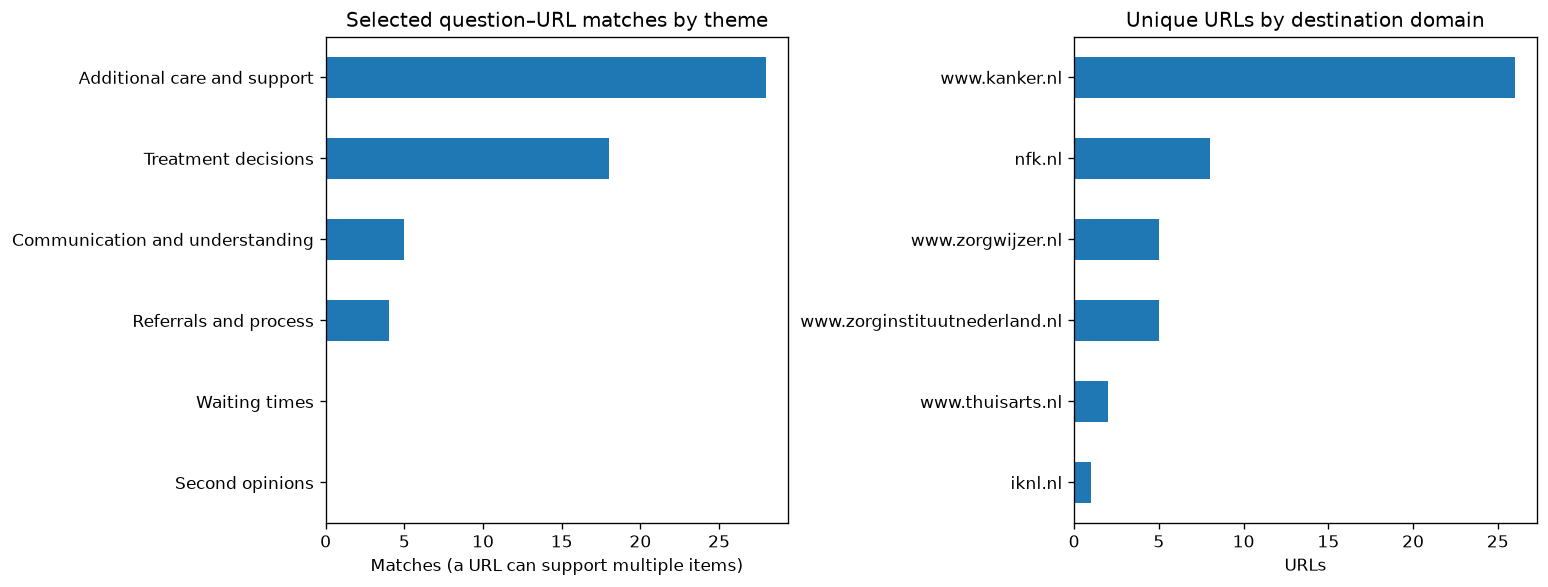

In [10]:
def join_unique(values):
    return "; ".join(dict.fromkeys(str(value) for value in values if pd.notna(value) and str(value)))

queue_rows = []
for canonical, group in selected_pairs_df.groupby("canonical_url"):
    best = group.sort_values("final_score", ascending=False).iloc[0]
    candidate = candidate_urls_df.iloc[int(best["candidate_index"])]
    queue_rows.append({
        "full_url":best["full_url"], "canonical_url":canonical,
        "destination_domain":best["destination_domain"], "destination_text":best["destination_text"],
        "matched_item_ids":join_unique(group["item_id"]), "matched_themes":join_unique(group["section_heading"]),
        "matched_item_count":group["item_id"].nunique(), "best_final_score":group["final_score"].max(),
        "best_tfidf_score":group["tfidf_score"].max(), "best_semantic_score":group["semantic_score"].max(),
        "matched_phrases":join_unique(group["matched_phrases"]),
        "selection_reason":join_unique(group["selection_reason"]),
        "metadata_review_notes":join_unique(group["review_note"]),
        "content_kind":candidate["content_kind"], "is_pdf_url":candidate["is_pdf_url"],
        "topic_cluster":candidate["topic_cluster"], "source_page_examples":candidate["source_page_examples"],
        "english_field_warning":candidate["english_field_warning"],
        "page_language":"not_checked", "page_content_checked":False, "scrape_status":"not_started",
    })
scraping_list_df = pd.DataFrame(queue_rows).sort_values(
    ["best_final_score", "matched_item_count", "canonical_url"], ascending=[False,False,True]
).reset_index(drop=True)
scraping_list_df.insert(0, "scrape_priority", np.arange(1,len(scraping_list_df)+1))
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 90):
    display(scraping_list_df[["scrape_priority", "full_url", "matched_item_ids", "destination_text"]])

fig, axes = plt.subplots(1, 2, figsize=(13,5))
coverage_df.groupby("section_heading")["selected_urls"].sum().sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Selected question–URL matches by theme")
axes[0].set_xlabel("Matches (a URL can support multiple items)")
axes[0].set_ylabel("")
scraping_list_df["destination_domain"].value_counts().sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Unique URLs by destination domain")
axes[1].set_xlabel("URLs")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ranking_coverage.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

## 11. Save the results without scraping

`candidate_scraping_list.csv` is the final queue, and `scraping_urls.txt` is the plain URL list.
The other files explain the decisions, preserve retrieved pair scores, record coverage gaps and provide a review sample.

Model revisions, package versions, input hashes and settings are saved in a manifest so this run can be reproduced. No candidate URL has been requested or scraped.

In [11]:
best_scores = selection_df.sort_values("final_score", ascending=False).drop_duplicates("canonical_url")
audit_df = prepared_urls_df.drop(columns=["link_labels_en"]).merge(
    best_scores[["canonical_url", "final_score", "item_id"]].rename(columns={"item_id":"best_matching_item_id"}),
    on="canonical_url", how="left", validate="many_to_one",
)
audit_df["selected_for_scraping"] = audit_df["canonical_url"].isin(scraping_list_df["canonical_url"])
audit_df["final_decision"] = np.select(
    [audit_df["selected_for_scraping"], audit_df["filter_status"].eq("exclude"), audit_df["filter_status"].eq("review")],
    ["selected", "excluded_by_rule", "needs_review"], default="not_shortlisted",
)
review_sample_df = pd.concat([
    selection_df.groupby("item_id").head(5),
    selection_df.loc[selection_df["selection_status"].eq("selected")],
    selection_df.loc[selection_df["selection_status"].ne("selected")].groupby("item_id").sample(n=2, random_state=42),
]).drop_duplicates(["item_id", "full_url"]).copy()
review_sample_df["human_relevance_label"] = ""
review_sample_df["human_review_notes"] = ""
cluster_summary_df = cluster_summary_df.merge(
    scraping_list_df.groupby("topic_cluster").size().rename("selected_urls"),
    on="topic_cluster", how="left",
).fillna({"selected_urls":0})
outputs = {
    "candidate_scraping_list.csv":scraping_list_df,
    "candidate_url_audit.csv":audit_df,
    "question_url_scores.csv":selection_df,
    "question_coverage.csv":coverage_df,
    "ranking_review_sample.csv":review_sample_df,
    "method_comparison.csv":method_comparison_df,
    "method_check_details.csv":method_checks_df,
    "selection_sensitivity.csv":sensitivity_df,
    "candidate_topic_clusters.csv":cluster_summary_df,
}
for filename, table in outputs.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
(OUTPUT_DIR / "scraping_urls.txt").write_text("\n".join(scraping_list_df["full_url"])+"\n")
input_files = [DATA_DIR / "interim" / name for name in [
    "community_search_items.csv", "discovered_urls_for_scoring.csv", "discovered_links_enriched.csv",
]] + sorted(REFERENCE_DIR.glob("*.csv")) + sorted(REFERENCE_DIR.glob("*.json"))
manifest = {
    "inputs_sha256":{str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in input_files},
    "helper_sha256":hashlib.sha256(Path("../src/candidate_ranking.py").read_bytes()).hexdigest(),
    "models":models, "selection_policy":policy, "field_weights":FIELD_WEIGHTS,
    "versions":{name:importlib.metadata.version(name) for name in [
        "numpy","pandas","scikit-learn","scipy","sentence-transformers","transformers","torch",
    ]},
    "counts":{"input_urls":len(prepared_urls_df), "scored_urls":len(candidate_urls_df),
              "retrieved_pairs":len(selection_df), "selected_urls":len(scraping_list_df)},
    "page_requests":0, "evaluation":"Assistant metadata development checks; no independent human labels",
}
(OUTPUT_DIR / "ranking_manifest.json").write_text(json.dumps(manifest, indent=2)+"\n")
print(f"Saved {len(scraping_list_df)} unique URLs ready for scraping to {OUTPUT_DIR}.")
print("Candidate pages fetched: 0")

Saved 47 unique URLs ready for scraping to ../data/processed.
Candidate pages fetched: 0


## Notes on the methods

The pipeline uses controlled phrases, query expansion, TF-IDF, cosine similarity, semantic embeddings, rank fusion, cross-encoder reranking, exploratory clustering and diversity controls. It also compares methods on a small metadata development set and checks selection sensitivity.

The search expansions and metadata reviews were authored by the assistant. Human labels and page contents are still needed to measure real answer coverage and retrieval quality. The score thresholds are practical starting settings, not an established optimum.

References: [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [Sentence Transformers retrieval and reranking](https://www.sbert.net/examples/sentence_transformer/applications/retrieve_rerank/README.html), [English retrieval model](https://huggingface.co/sentence-transformers/multi-qa-MiniLM-L6-cos-v1).